In [5]:
from supabase import create_client, Client
import pandas as pd
import numpy as np

SUPABASE_URL = "https://mmcczchanckdfsqnnmep.supabase.co"

# service_role key — bypasses RLS, sees ALL users' data
SUPABASE_SERVICE_KEY = "sb_secret_70mZQxD9rgzUO0B8qA-WFg_rXqLnxY2"

supabase: Client = create_client(SUPABASE_URL, SUPABASE_SERVICE_KEY)

# Test it
txn_res = supabase.table("user_transactions").select("*").execute()
fin_res = supabase.table("user_finances").select("*").execute()

print(f" Transactions: {len(txn_res.data)} rows")
print(f" Finances:     {len(fin_res.data)} rows")

# Preview
if txn_res.data:
    print("\nColumns:", list(txn_res.data[0].keys()))
    print("Sample:", txn_res.data[0])

 Transactions: 52 rows
 Finances:     10 rows

Columns: ['id', 'user_id', 'name', 'amount', 'type', 'category', 'emoji', 'logo', 'notes', 'created_at']
Sample: {'id': 'a2e95c63-d803-48f3-a347-dec1dcdae5ff', 'user_id': '81a994e9-72e9-4de1-a954-01dbac7e37f3', 'name': 'Deposit', 'amount': 32.0, 'type': 'deposit', 'category': 'Income', 'emoji': '💰', 'logo': None, 'notes': None, 'created_at': '2026-02-20T15:33:41.272+00:00'}


In [6]:
# Debug cell — run this before anything else
print("=== user_transactions ===")
print(f"Rows: {len(txn_res.data)}")
print(f"Data: {txn_res.data[:3]}")  # first 3 rows

print("\n=== user_finances ===")
print(f"Rows: {len(fin_res.data)}")
print(f"Data: {fin_res.data[:3]}")

print("\n=== df_txn columns ===")
print(df_txn.columns.tolist())
print(df_txn.shape)

=== user_transactions ===
Rows: 52
Data: [{'id': 'a2e95c63-d803-48f3-a347-dec1dcdae5ff', 'user_id': '81a994e9-72e9-4de1-a954-01dbac7e37f3', 'name': 'Deposit', 'amount': 32.0, 'type': 'deposit', 'category': 'Income', 'emoji': '💰', 'logo': None, 'notes': None, 'created_at': '2026-02-20T15:33:41.272+00:00'}, {'id': '7bdb8fad-87e4-4fe3-8be2-33118837b438', 'user_id': '81a994e9-72e9-4de1-a954-01dbac7e37f3', 'name': 'Deposit', 'amount': 32.0, 'type': 'deposit', 'category': 'Income', 'emoji': '💰', 'logo': None, 'notes': None, 'created_at': '2026-02-20T15:33:42.905+00:00'}, {'id': 'dc6e0f9f-8879-4036-8063-8aec8ebcb9ff', 'user_id': '81a994e9-72e9-4de1-a954-01dbac7e37f3', 'name': 'Deposit', 'amount': 322333.0, 'type': 'deposit', 'category': 'Income', 'emoji': '💰', 'logo': None, 'notes': None, 'created_at': '2026-02-20T15:51:26.204+00:00'}]

=== user_finances ===
Rows: 10
Data: [{'id': '94c79464-6f31-4d0b-8d28-6d4415d47c6e', 'user_id': '8083dde7-b9c4-47a8-ab80-403db23bbfa3', 'balance': 5000.0, 'to

# Load & clean

In [7]:
df_txn = pd.DataFrame(txn_res.data)
df_fin = pd.DataFrame(fin_res.data)

df_txn["created_at"] = pd.to_datetime(df_txn["created_at"], utc=True)
df_txn["amount"] = df_txn["amount"].astype(float)
df_txn["month"] = df_txn["created_at"].dt.to_period("M")

print(f" {len(df_txn)} transactions | {df_txn['user_id'].nunique()} users")
print(f"\nTransaction types:\n{df_txn['type'].value_counts()}")
print(f"\nCategories:\n{df_txn['category'].value_counts()}")
print(f"\nDate range: {df_txn['created_at'].min().date()} → {df_txn['created_at'].max().date()}")

 52 transactions | 8 users

Transaction types:
type
expense    31
deposit    21
Name: count, dtype: int64

Categories:
category
Income           21
Subscriptions    16
Shopping          5
Bills             3
Dining            2
Transport         2
Other             2
Groceries         1
Name: count, dtype: int64

Date range: 2026-02-15 → 2026-03-04


/var/folders/_l/vdgqbw4x0q99dgnnpmyn9v3m0000gn/T/ipykernel_2557/3198591230.py:6: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_txn["month"] = df_txn["created_at"].dt.to_period("M")


# Quick EDA plots

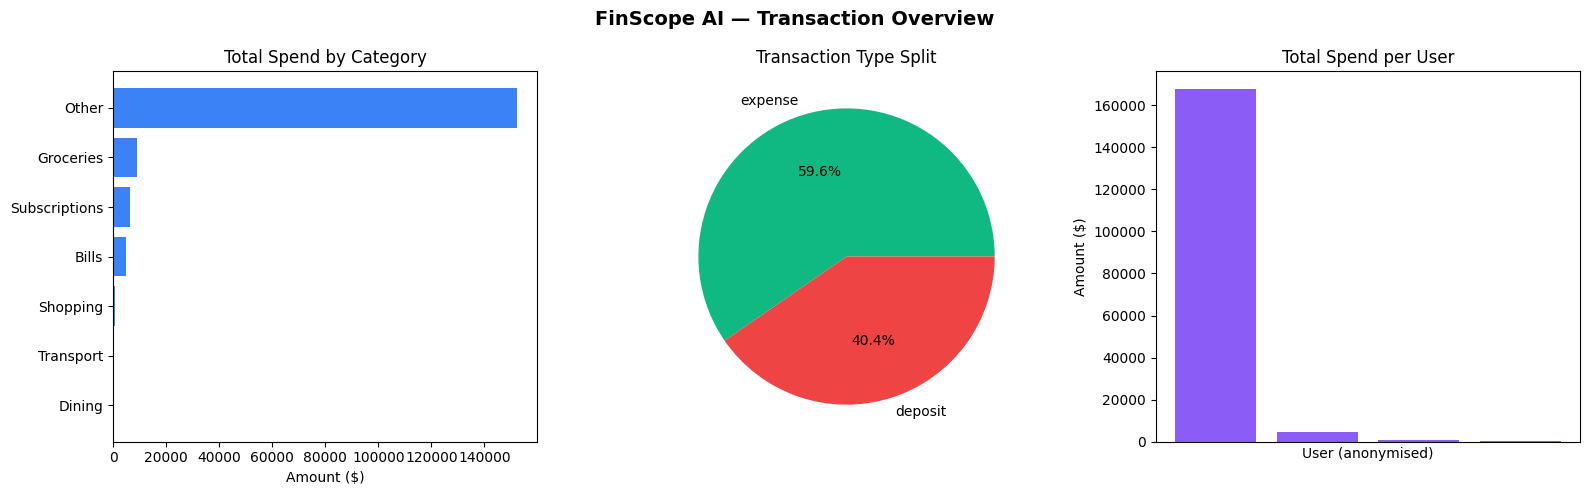

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("FinScope AI — Transaction Overview", fontsize=14, fontweight="bold")

# Plot 1: spend by category
expenses = df_txn[df_txn["type"] == "expense"]
cat_totals = expenses.groupby("category")["amount"].sum().sort_values(ascending=True)
axes[0].barh(cat_totals.index, cat_totals.values, color="#3b82f6")
axes[0].set_title("Total Spend by Category")
axes[0].set_xlabel("Amount ($)")

# Plot 2: transaction type split
type_counts = df_txn["type"].value_counts()
axes[1].pie(type_counts.values, labels=type_counts.index,
            autopct="%1.1f%%", colors=["#10b981", "#ef4444", "#f59e0b"])
axes[1].set_title("Transaction Type Split")

# Plot 3: spend per user
user_spend = expenses.groupby("user_id")["amount"].sum().sort_values(ascending=False)
axes[2].bar(range(len(user_spend)), user_spend.values, color="#8b5cf6")
axes[2].set_title("Total Spend per User")
axes[2].set_xlabel("User (anonymised)")
axes[2].set_ylabel("Amount ($)")
axes[2].set_xticks([])

plt.tight_layout()
plt.show()

# Build user feature matrix for clustering

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Category spend per user (expenses only)
cat_pivot = expenses.groupby(["user_id", "category"])["amount"]\
                    .sum().unstack(fill_value=0)

# Join finance summary
fin_indexed = df_fin.set_index("user_id")[["balance", "total_income", "total_expenses"]]
user_features = cat_pivot.join(fin_indexed, how="left").fillna(0)

# Derived features
user_features["savings_rate"] = (
    (user_features["total_income"] - user_features["total_expenses"])
    / user_features["total_income"].replace(0, np.nan)
).fillna(0).clip(0, 1)

user_features["txn_count"]    = expenses.groupby("user_id").size().reindex(user_features.index, fill_value=0)
user_features["avg_txn_size"] = expenses.groupby("user_id")["amount"].mean().reindex(user_features.index, fill_value=0)

print(f" Feature matrix: {user_features.shape[0]} users × {user_features.shape[1]} features")
print(user_features.round(2))

 Feature matrix: 4 users × 13 features
                                       Bills  Dining  Groceries     Other  \
user_id                                                                     
81a994e9-72e9-4de1-a954-01dbac7e37f3  4821.0   100.0     8900.0  152332.0   
a9c0974d-dc7e-42ce-b9b5-28159c62f649     0.0     0.0        0.0       0.0   
bbbba7eb-c6cd-40ac-9068-acd0bc34df5b     0.0     0.0        0.0       0.0   
e7614297-8f8a-43a4-bbfe-ea8b4c107c7d   100.0   100.0        0.0       0.0   

                                      Shopping  Subscriptions  Transport  \
user_id                                                                    
81a994e9-72e9-4de1-a954-01dbac7e37f3    721.00         632.00      200.0   
a9c0974d-dc7e-42ce-b9b5-28159c62f649      0.00         400.00        0.0   
bbbba7eb-c6cd-40ac-9068-acd0bc34df5b      0.00        4696.00        0.0   
e7614297-8f8a-43a4-bbfe-ea8b4c107c7d      0.01         554.97      200.0   

                                         

# Elbow method + cluster

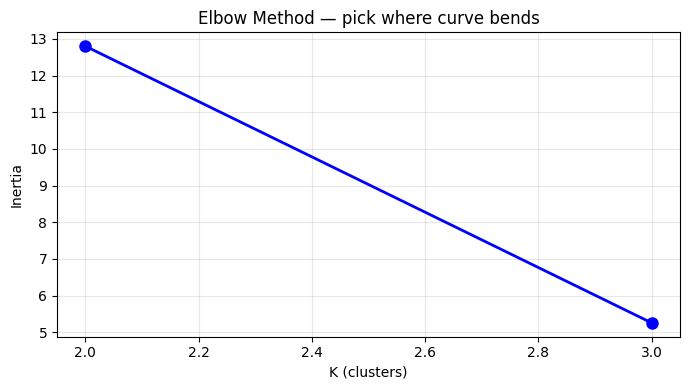

In [10]:
X = StandardScaler().fit_transform(user_features)

inertias = []
K_range = range(2, min(8, len(user_features)))
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    inertias.append(km.fit(X).inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(K_range), inertias, "bo-", linewidth=2, markersize=8)
plt.xlabel("K (clusters)"); plt.ylabel("Inertia")
plt.title("Elbow Method — pick where curve bends")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()